# Exploratory Data Analysis dan Preprocessing — Hotel Booking Demand

Dimulai dari **dataset mentah** `hotel_bookings.csv` berasal dari sumber dataset Hotel Booking Demand, analisis dilakukan melalui tahapan eksplorasi data (Exploratory Data Analysis atau EDA) dan prapemrosesan data (data preprocessing). Tahapan ini mencakup pemeriksaan struktur dan tipe data, analisis statistik deskriptif, identifikasi nilai yang hilang (missing values), pemeriksaan duplikasi data, serta visualisasi distribusi dan pencilan (outliers) pada variabel numerik. Selanjutnya, dilakukan penanganan nilai yang hilang dan duplikasi sesuai dengan karakteristik data agar dataset lebih siap digunakan untuk analisis lanjutan.

**Prinsip:** data mentah (`df_raw`) tidak diubah. Analisis awal menggunakan `df`, sedangkan hasil preprocessing disimpan terpisah sebagai `df_clean`. Kandidat outlier tidak otomatis dihapus karena perlu penilaian konteks.

## 1. Import library dan pengaturan tampilan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from google.colab import files
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.3f}".format)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Library berhasil diimpor.")

Library berhasil diimpor.


## 2. Upload dan membaca dataset mentah

In [2]:
uploaded = files.upload()
nama_file = next(iter(uploaded))

df_raw = pd.read_csv(nama_file)
df = df_raw.copy()

print("Dataset berhasil dibaca.")
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])

Saving hotel_bookings.csv to hotel_bookings.csv
Dataset berhasil dibaca.
Jumlah baris : 119390
Jumlah kolom : 32


In [3]:
display(df.head())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,01-07-15
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,01-07-15
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.000,0,0,Check-Out,02-07-15
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.000,NaN,0,Transient,75.000,0,0,Check-Out,02-07-15
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,03-07-15


In [4]:
display(df.tail())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.000,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.000,NaN,0,Transient,96.140,0,0,Check-Out,06-09-17
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.000,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.000,NaN,0,Transient,225.430,0,2,Check-Out,07-09-17
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.000,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.000,NaN,0,Transient,157.710,0,4,Check-Out,07-09-17
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.000,NaN,0,Transient,104.400,0,0,Check-Out,07-09-17
119389,City Hotel,0,205,2017,August,35,29,2,7,2,0.000,0,HB,DEU,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.000,NaN,0,Transient,151.200,0,2,Check-Out,07-09-17


## 3. Struktur dan tipe variabel

In [5]:
print("Dimensi DataFrame:", df.shape)
print("\nDaftar kolom:")
print(df.columns.tolist())

print("\nInformasi DataFrame:")
df.info()

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nJumlah variabel numerik:", len(numeric_cols))
print(numeric_cols)
print("\nJumlah variabel kategorik:", len(categorical_cols))
print(categorical_cols)

Dimensi DataFrame: (119390, 32)

Daftar kolom:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']

Informasi DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_cancele

## 4. Statistik deskriptif

In [6]:
print("STATISTIK DESKRIPTIF NUMERIK")
display(df.describe().T)

print("STATISTIK DESKRIPTIF KATEGORIK")
display(df.describe(include=["object", "category"]).T)

STATISTIK DESKRIPTIF NUMERIK


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.000,0.370,0.483,0.000,0.000,0.000,1.000,1.000
lead_time,119390.000,104.011,106.863,0.000,18.000,69.000,160.000,737.000
arrival_date_year,119390.000,2016.157,0.707,2015.000,2016.000,2016.000,2017.000,2017.000
arrival_date_week_number,119390.000,27.165,13.605,1.000,16.000,28.000,38.000,53.000
arrival_date_day_of_month,119390.000,15.798,8.781,1.000,8.000,16.000,23.000,31.000
stays_in_weekend_nights,119390.000,0.928,0.999,0.000,0.000,1.000,2.000,19.000
stays_in_week_nights,119390.000,2.500,1.908,0.000,1.000,2.000,3.000,50.000
adults,119390.000,1.856,0.579,0.000,2.000,2.000,2.000,55.000
children,119386.000,0.104,0.399,0.000,0.000,0.000,0.000,10.000
babies,119390.000,0.008,0.097,0.000,0.000,0.000,0.000,10.000


STATISTIK DESKRIPTIF KATEGORIK


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


In [7]:
desc = df[numeric_cols].describe().T
desc["median"] = df[numeric_cols].median()
desc["skewness"] = df[numeric_cols].skew()
desc["kurtosis (excess)"] = df[numeric_cols].kurtosis()
desc["missing"] = df[numeric_cols].isna().sum()

display(desc.round(3))

,count,mean,std,min,25%,50%,75%,max,median,skewness,kurtosis (excess),missing
is_canceled,119390.000,0.370,0.483,0.000,0.000,0.000,1.000,1.000,0.000,0.537,-1.712,0
lead_time,119390.000,104.011,106.863,0.000,18.000,69.000,160.000,737.000,69.000,1.347,1.696,0
arrival_date_year,119390.000,2016.157,0.707,2015.000,2016.000,2016.000,2017.000,2017.000,2016.000,-0.233,-0.995,0
arrival_date_week_number,119390.000,27.165,13.605,1.000,16.000,28.000,38.000,53.000,28.000,-0.010,-0.986,0
arrival_date_day_of_month,119390.000,15.798,8.781,1.000,8.000,16.000,23.000,31.000,16.000,-0.002,-1.187,0
stays_in_weekend_nights,119390.000,0.928,0.999,0.000,0.000,1.000,2.000,19.000,1.000,1.380,7.174,0
stays_in_week_nights,119390.000,2.500,1.908,0.000,1.000,2.000,3.000,50.000,2.000,2.862,24.285,0
adults,119390.000,1.856,0.579,0.000,2.000,2.000,2.000,55.000,2.000,18.318,1352.115,0
children,119386.000,0.104,0.399,0.000,0.000,0.000,0.000,10.000,0.000,4.113,18.674,4
babies,119390.000,0.008,0.097,0.000,0.000,0.000,0.000,10.000,0.000,24.647,1633.948,0


## 5. Perbandingan mean dan median variabel numerik

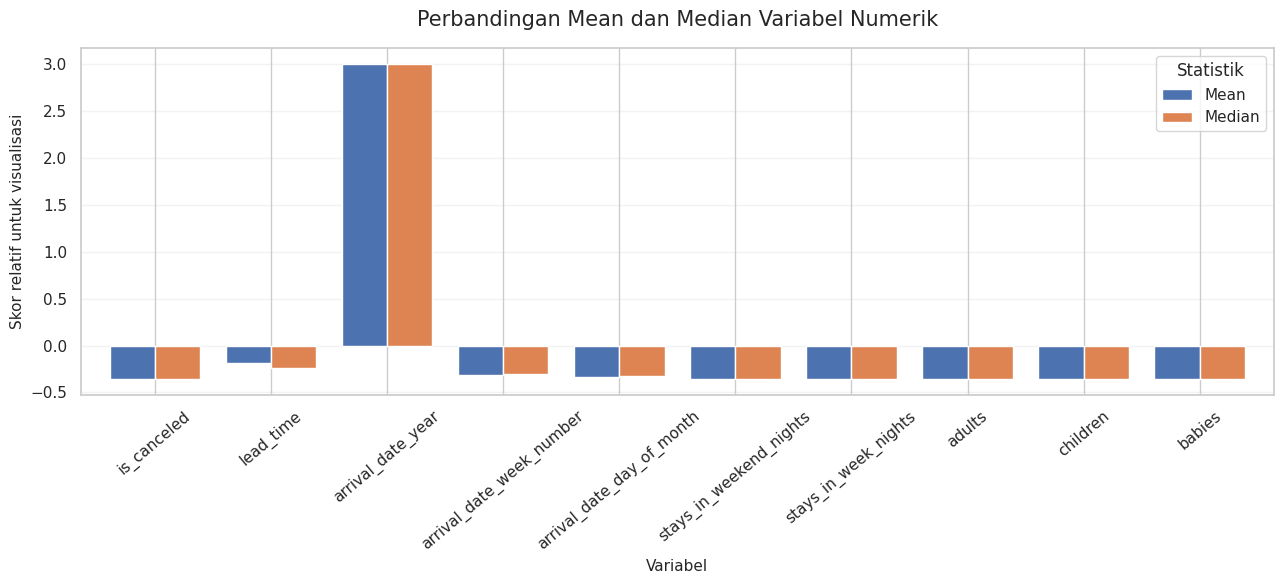

In [8]:
chart_cols = [
    c for c in numeric_cols
    if df[c].nunique(dropna=True) > 1
][:10]

if chart_cols:
    comparison = pd.DataFrame({
        "Mean": df[chart_cols].mean(),
        "Median": df[chart_cols].median()
    })

    comparison_z = (
        comparison - comparison.mean()
    ) / comparison.std(ddof=0).replace(0, 1)

    ax = comparison_z.plot(kind="bar", figsize=(13, 6), width=0.78)
    ax.set_title("Perbandingan Mean dan Median Variabel Numerik", fontsize=15, pad=16)
    ax.set_xlabel("Variabel")
    ax.set_ylabel("Skor relatif untuk visualisasi")
    ax.tick_params(axis="x", rotation=40)
    ax.legend(title="Statistik")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("Tidak tersedia variabel numerik dengan variasi yang memadai.")

## 6. Heatmap korelasi variabel numerik

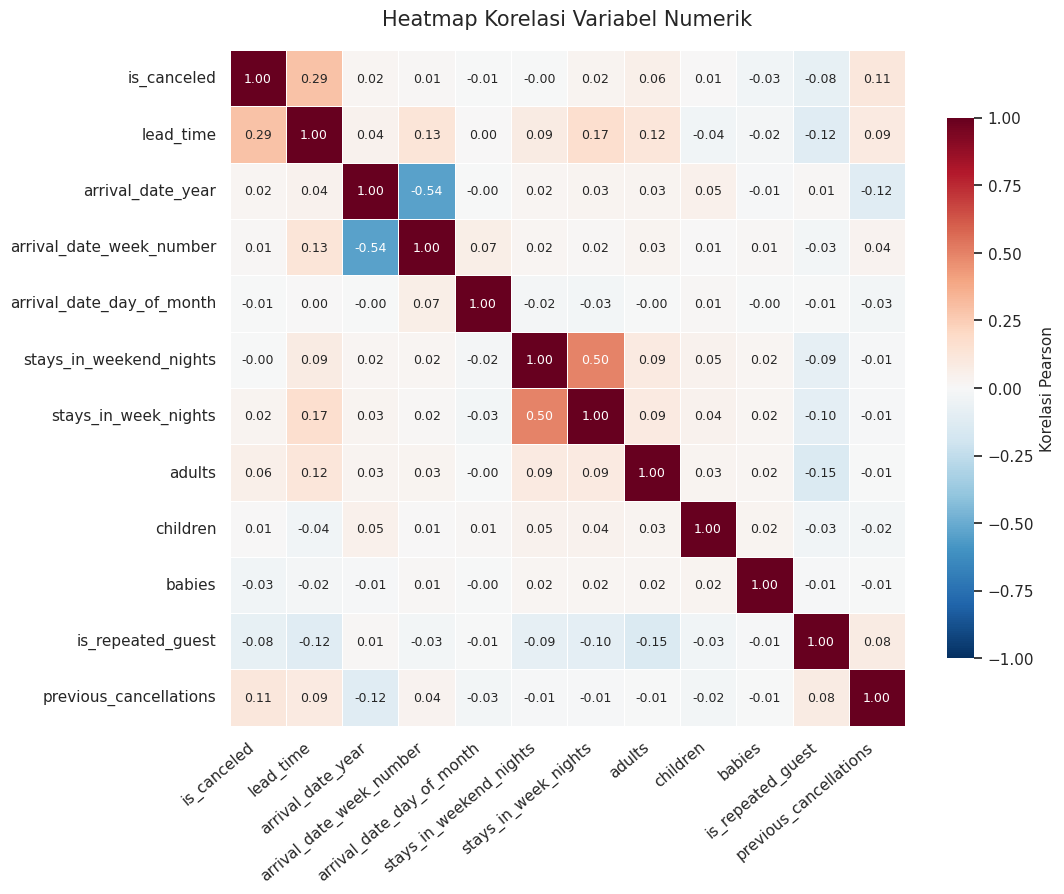

In [9]:
corr_cols = [
    c for c in numeric_cols
    if df[c].nunique(dropna=True) > 1
][:12]

if len(corr_cols) >= 2:
    corr = df[corr_cols].corr()

    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(
        corr, annot=True, fmt=".2f", cmap="RdBu_r",
        vmin=-1, vmax=1, center=0, square=True,
        linewidths=0.7, annot_kws={"size": 9},
        cbar_kws={"label": "Korelasi Pearson", "shrink": 0.8},
        ax=ax
    )
    ax.set_title("Heatmap Korelasi Variabel Numerik", fontsize=15, pad=18)
    plt.xticks(rotation=40, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Variabel numerik tidak cukup untuk menghitung korelasi.")

## 7. Pemeriksaan missing values pada data mentah

In [10]:
missing_report = pd.DataFrame({
    "Jumlah Missing": df.isna().sum(),
    "Persentase Missing (%)": (df.isna().mean() * 100).round(2),
    "Jumlah Terisi": df.notna().sum()
}).sort_values("Persentase Missing (%)", ascending=False)

display(missing_report)
display(missing_report[missing_report["Jumlah Missing"] > 0])

,Jumlah Missing,Persentase Missing (%),Jumlah Terisi
company,112593,94.310,6797
agent,16340,13.690,103050
country,488,0.410,118902
hotel,0,0.000,119390
arrival_date_month,0,0.000,119390
arrival_date_week_number,0,0.000,119390
lead_time,0,0.000,119390
is_canceled,0,0.000,119390
stays_in_weekend_nights,0,0.000,119390
stays_in_week_nights,0,0.000,119390


,Jumlah Missing,Persentase Missing (%),Jumlah Terisi
company,112593,94.310,6797
agent,16340,13.690,103050
country,488,0.410,118902
children,4,0.000,119386


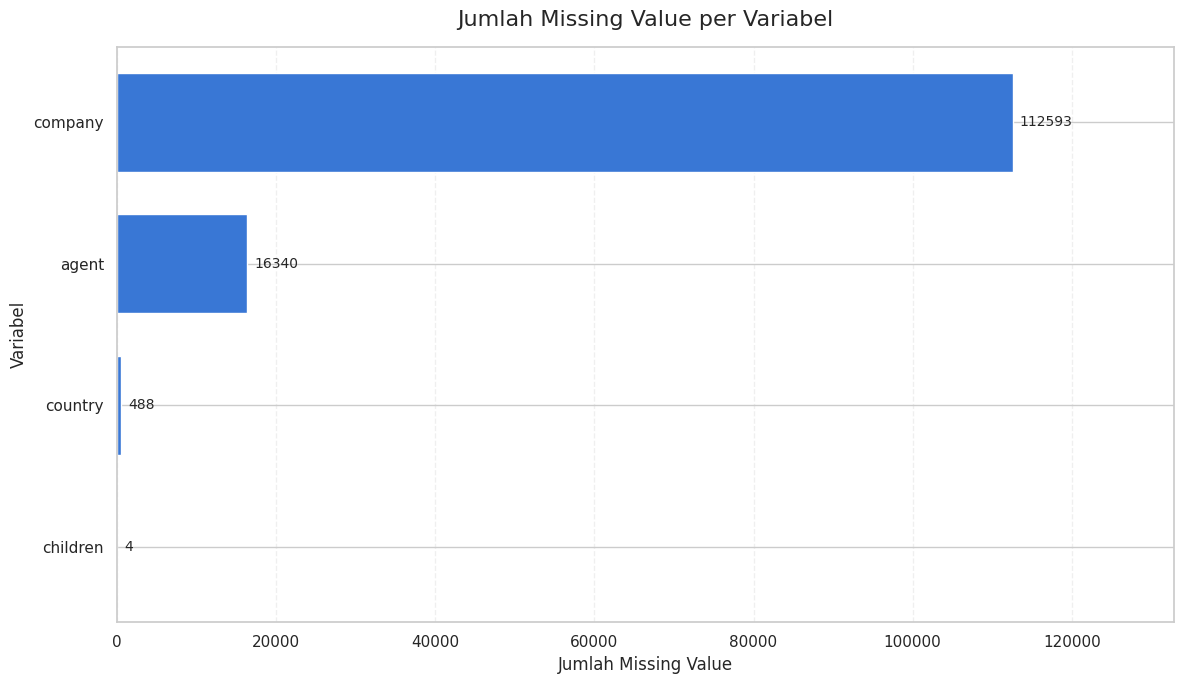

In [11]:
missing_count = df.isna().sum()
missing_count = missing_count[missing_count > 0].sort_values(ascending=True)

if not missing_count.empty:
    fig, ax = plt.subplots(figsize=(12, 7))
    bars = ax.barh(
        missing_count.index, missing_count.values,
        color="#3977D5", edgecolor="white", height=0.7
    )
    ax.bar_label(bars, fmt="%.0f", padding=5, fontsize=10)
    ax.set_xlim(0, missing_count.max() * 1.18)
    ax.set_title("Jumlah Missing Value per Variabel", fontsize=16, pad=15)
    ax.set_xlabel("Jumlah Missing Value", fontsize=12)
    ax.set_ylabel("Variabel", fontsize=12)
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ditemukan missing value pada dataset.")

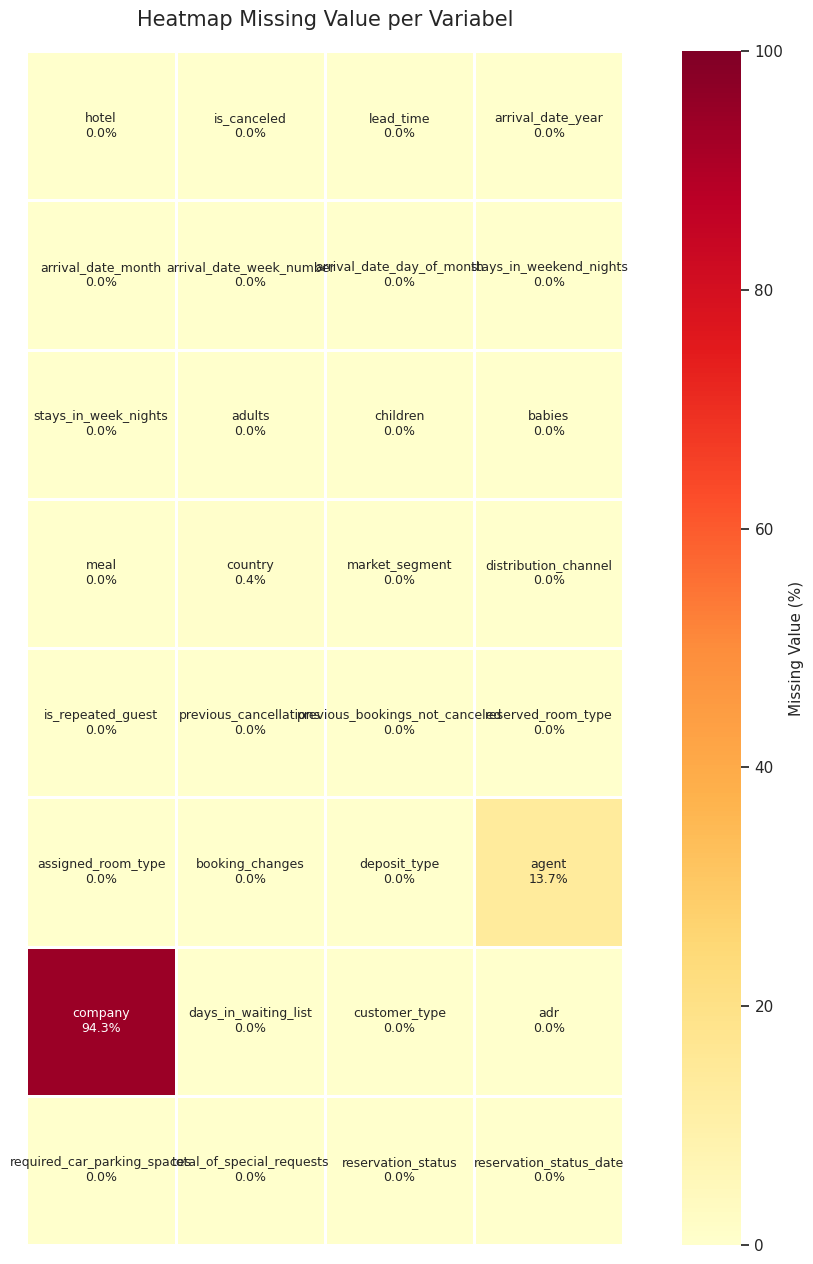

In [12]:
import math

missing_pct = df.isna().mean() * 100
n_cols_grid = 4
n_rows_grid = math.ceil(len(missing_pct) / n_cols_grid)

values = np.full((n_rows_grid, n_cols_grid), np.nan)
labels = np.full((n_rows_grid, n_cols_grid), "", dtype=object)

for i, (col, pct) in enumerate(missing_pct.items()):
    r, c = divmod(i, n_cols_grid)
    values[r, c] = pct
    labels[r, c] = f"{col}\n{pct:.1f}%"

fig, ax = plt.subplots(figsize=(12, max(4, n_rows_grid * 1.6)))
sns.heatmap(
    values, annot=labels, fmt="", mask=np.isnan(values),
    cmap="YlOrRd", vmin=0, vmax=100, square=True,
    linewidths=2, linecolor="white",
    cbar_kws={"label": "Missing Value (%)"},
    annot_kws={"fontsize": 9}, ax=ax
)
ax.set_title("Heatmap Missing Value per Variabel", fontsize=15, pad=18)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.tick_params(left=False, bottom=False)
plt.tight_layout()
plt.show()

## 8. Pemeriksaan duplikasi dan konsistensi nilai

In [13]:
jumlah_duplikat = df.duplicated().sum()
print("Jumlah baris duplikat penuh:", jumlah_duplikat)
display(df[df.duplicated(keep=False)].head(10))

Jumlah baris duplikat penuh: 31994


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,03-07-15
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,03-07-15
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,A,A,1,No Deposit,250.000,NaN,0,Transient,84.670,0,1,Check-Out,07-07-15
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,A,A,1,No Deposit,250.000,NaN,0,Transient,84.670,0,1,Check-Out,07-07-15
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,0.000,0,HB,ROU,Direct,Direct,0,0,0,E,E,0,No Deposit,250.000,NaN,0,Transient,137.000,0,1,Check-Out,07-07-15
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,0.000,0,HB,ROU,Direct,Direct,0,0,0,E,E,0,No Deposit,250.000,NaN,0,Transient,137.000,0,1,Check-Out,07-07-15
132,Resort Hotel,1,5,2015,July,28,5,1,0,2,0.000,0,BB,PRT,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,240.000,NaN,0,Transient,97.000,0,0,Canceled,01-07-15
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,0.000,0,BB,PRT,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,240.000,NaN,0,Transient,97.000,0,0,Canceled,01-07-15
198,Resort Hotel,0,0,2015,July,28,7,0,1,1,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,109.800,0,3,Check-Out,08-07-15
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,109.800,0,3,Check-Out,08-07-15


In [14]:
print("Ringkasan nilai minimum dan maksimum:")
display(df[numeric_cols].agg(["min", "max"]).T)

Ringkasan nilai minimum dan maksimum:


,min,max
is_canceled,0.000,1.000
lead_time,0.000,737.000
arrival_date_year,2015.000,2017.000
arrival_date_week_number,1.000,53.000
arrival_date_day_of_month,1.000,31.000
stays_in_weekend_nights,0.000,19.000
stays_in_week_nights,0.000,50.000
adults,0.000,55.000
children,0.000,10.000
babies,0.000,10.000


In [15]:
kolom_cek = [
    "children", "adults", "babies", "lead_time",
    "stays_in_weekend_nights", "stays_in_week_nights", "adr"
]

for col in kolom_cek:
    if col in df.columns:
        x = pd.to_numeric(df[col], errors="coerce")
        print(f"\nKolom: {col}")
        print("Nilai negatif:", int((x < 0).sum()))
        print("Nilai nol:", int((x == 0).sum()))


Kolom: children
Nilai negatif: 0
Nilai nol: 110796

Kolom: adults
Nilai negatif: 0
Nilai nol: 403

Kolom: babies
Nilai negatif: 0
Nilai nol: 118473

Kolom: lead_time
Nilai negatif: 0
Nilai nol: 6345

Kolom: stays_in_weekend_nights
Nilai negatif: 0
Nilai nol: 51998

Kolom: stays_in_week_nights
Nilai negatif: 0
Nilai nol: 7645

Kolom: adr
Nilai negatif: 1
Nilai nol: 1959


## 9. Distribusi ADR

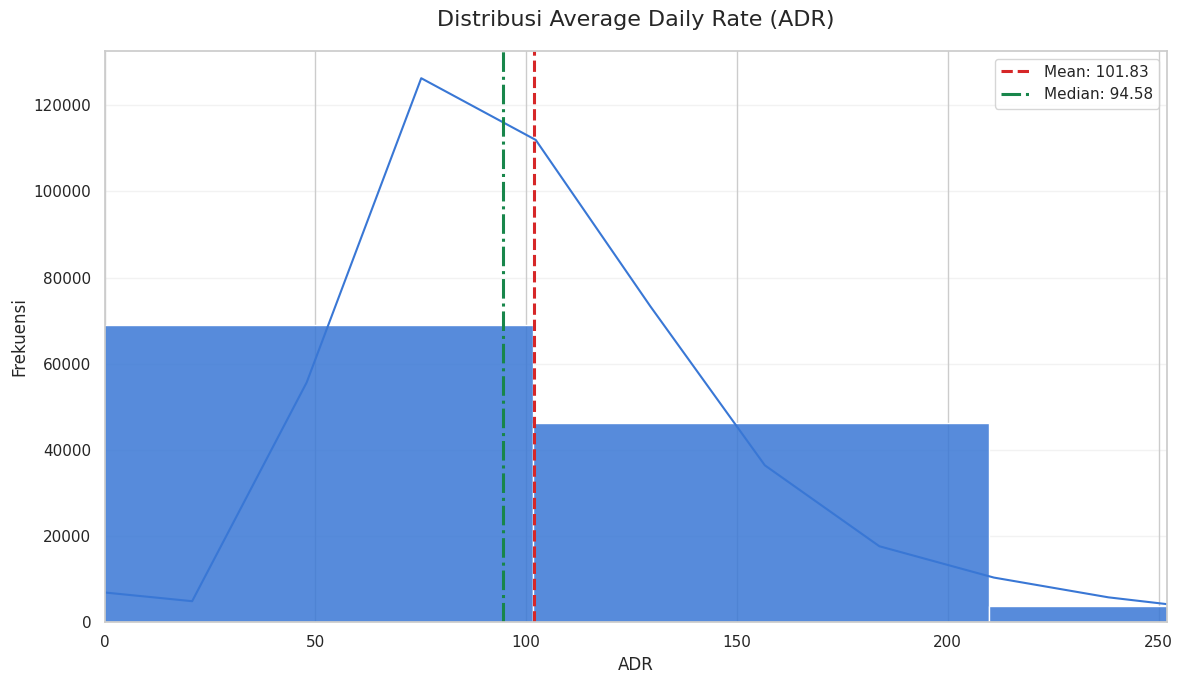

Jumlah observasi valid: 119,390
Mean: 101.831
Median: 94.575
Skewness: 10.530
Kurtosis: 1013.190


In [16]:
if "adr" in df.columns:
    x = pd.to_numeric(df["adr"], errors="coerce").dropna()
    x = x[np.isfinite(x)]

    fig, ax = plt.subplots(figsize=(12, 7))
    sns.histplot(
        x, bins=50, kde=True, color="#3977D5",
        edgecolor="white", alpha=0.85, ax=ax
    )
    ax.axvline(x.mean(), color="#D62728", linestyle="--", linewidth=2.2,
               label=f"Mean: {x.mean():.2f}")
    ax.axvline(x.median(), color="#18864B", linestyle="-.", linewidth=2.2,
               label=f"Median: {x.median():.2f}")

    ax.set_xlim(x.quantile(0.01), x.quantile(0.99))
    ax.set_title("Distribusi Average Daily Rate (ADR)", fontsize=16, pad=18)
    ax.set_xlabel("ADR", fontsize=12)
    ax.set_ylabel("Frekuensi", fontsize=12)
    ax.legend(fontsize=11)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

    print(f"Jumlah observasi valid: {len(x):,}")
    print(f"Mean: {x.mean():.3f}")
    print(f"Median: {x.median():.3f}")
    print(f"Skewness: {x.skew():.3f}")
    print(f"Kurtosis: {x.kurtosis():.3f}")

## 10. Boxplot ADR: zoom dan rentang penuh

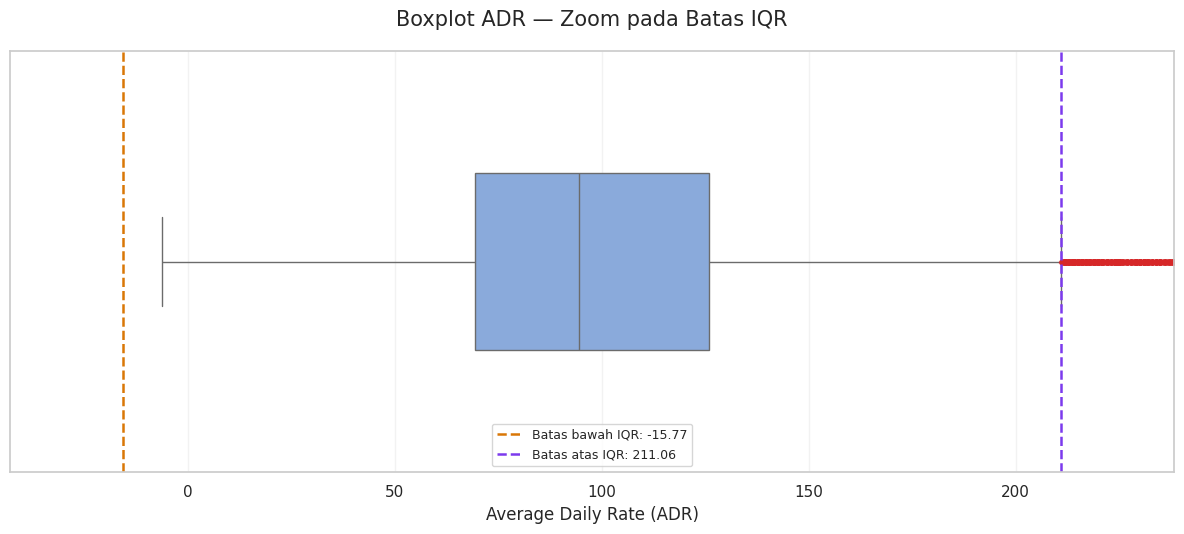

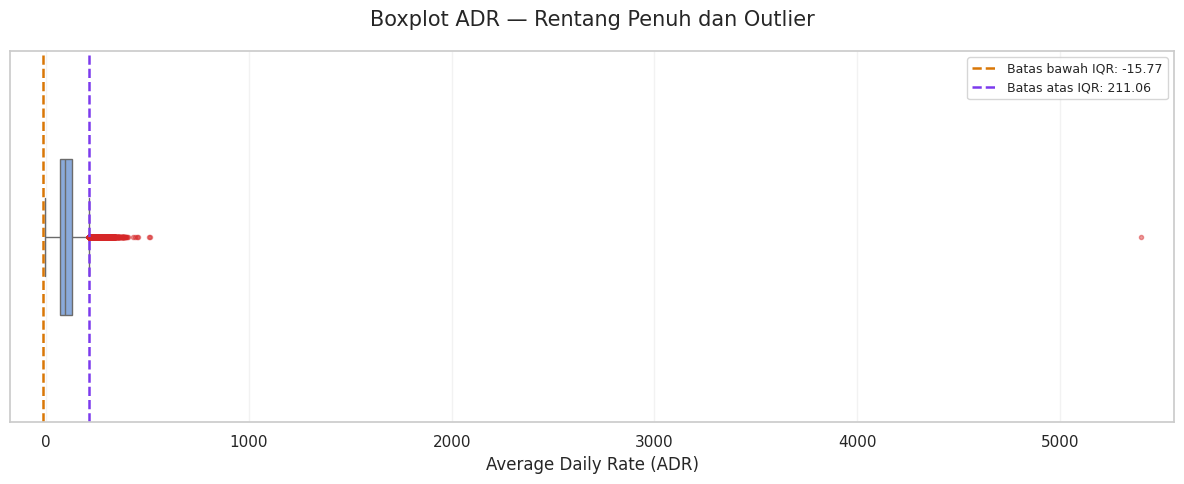

Q1: 69.290 | Q3: 126.000 | IQR: 56.710
Batas bawah: -15.775 | Batas atas: 211.065
Jumlah kandidat outlier: 3,793


In [17]:
if "adr" in df.columns:
    x = pd.to_numeric(df["adr"], errors="coerce").dropna()
    x = x[np.isfinite(x)]

    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    padding = max((upper - lower) * 0.12, 1)

    flierprops = {
        "marker": "o", "markersize": 3,
        "markerfacecolor": "#D62728",
        "markeredgecolor": "#D62728", "alpha": 0.45
    }

    # Grafik 1: fokus pada rentang IQR;
    fig, ax = plt.subplots(figsize=(12, 5.5))
    sns.boxplot(x=x, color="#7DA7E8", width=0.42,
                showfliers=True, flierprops=flierprops, ax=ax)
    ax.set_xlim(lower - padding, upper + padding)
    ax.axvline(lower, color="#D97706", linestyle="--", linewidth=1.8,
               label=f"Batas bawah IQR: {lower:.2f}")
    ax.axvline(upper, color="#7C3AED", linestyle="--", linewidth=1.8,
               label=f"Batas atas IQR: {upper:.2f}")
    ax.set_title("Boxplot ADR — Zoom pada Batas IQR", fontsize=15, pad=18)
    ax.set_xlabel("Average Daily Rate (ADR)", fontsize=12)
    ax.legend(fontsize=9)
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

    # Grafik 2: rentang penuh agar pencilan ekstrem tetap dapat diperiksa.
    fig, ax = plt.subplots(figsize=(12, 5))
    sns.boxplot(x=x, color="#7DA7E8", width=0.42,
                showfliers=True, flierprops=flierprops, ax=ax)
    full_min = min(float(x.min()), float(lower))
    full_max = max(float(x.max()), float(upper))
    full_padding = max((full_max - full_min) * 0.03, 1)
    ax.set_xlim(full_min - full_padding, full_max + full_padding)
    ax.axvline(lower, color="#D97706", linestyle="--", linewidth=1.8,
               label=f"Batas bawah IQR: {lower:.2f}")
    ax.axvline(upper, color="#7C3AED", linestyle="--", linewidth=1.8,
               label=f"Batas atas IQR: {upper:.2f}")
    ax.set_title("Boxplot ADR — Rentang Penuh dan Outlier", fontsize=15, pad=18)
    ax.set_xlabel("Average Daily Rate (ADR)", fontsize=12)
    ax.legend(fontsize=9)
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

    print(f"Q1: {q1:.3f} | Q3: {q3:.3f} | IQR: {iqr:.3f}")
    print(f"Batas bawah: {lower:.3f} | Batas atas: {upper:.3f}")
    print(f"Jumlah kandidat outlier: {((x < lower) | (x > upper)).sum():,}")

## 11. Boxplot tiap variabel dan IQR

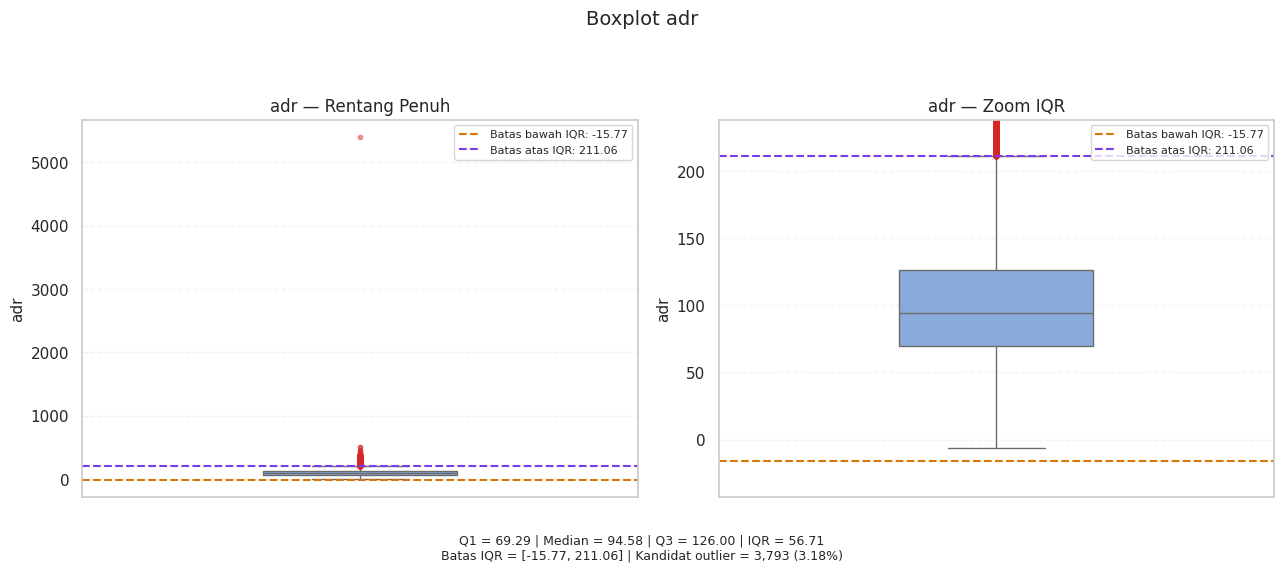

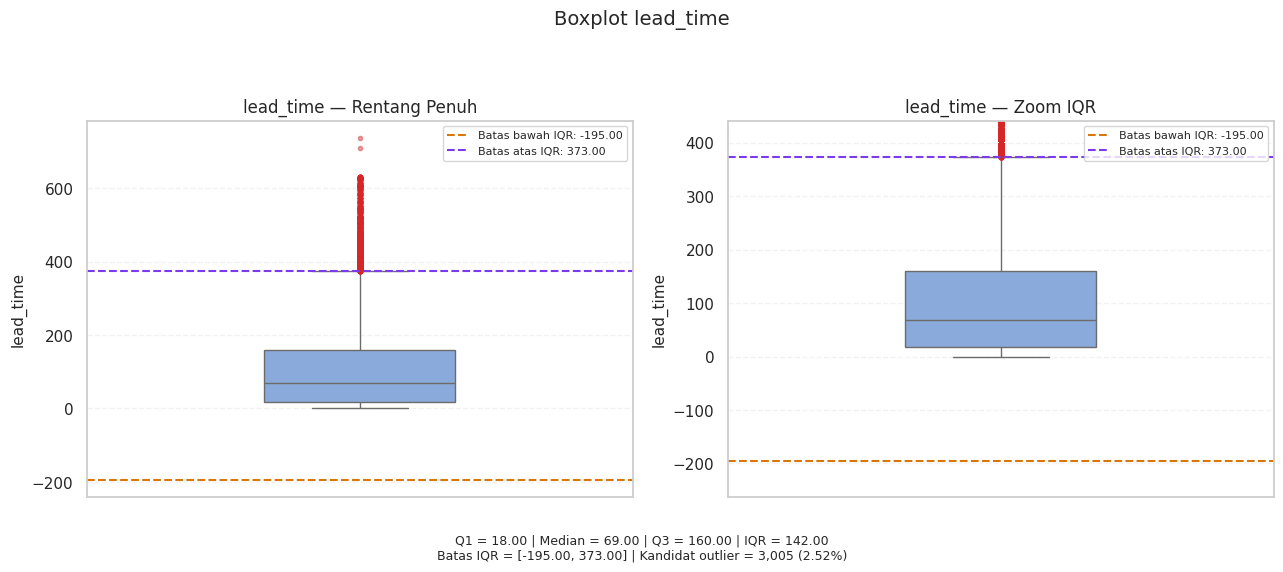

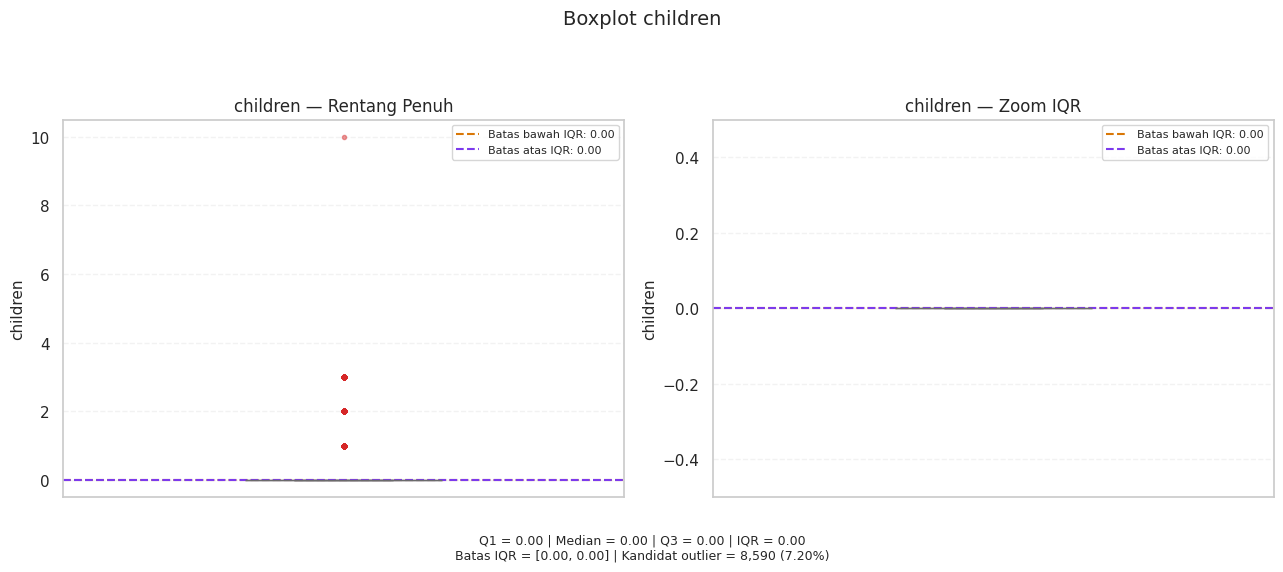

Catatan children: IQR = 0 (Q1 = Q3). Kotak dapat tampak seperti garis karena setidaknya 50% data terkonsentrasi pada nilai yang sama. Ini dapat terjadi pada variabel hitungan yang didominasi angka nol; bukan otomatis kesalahan grafik.


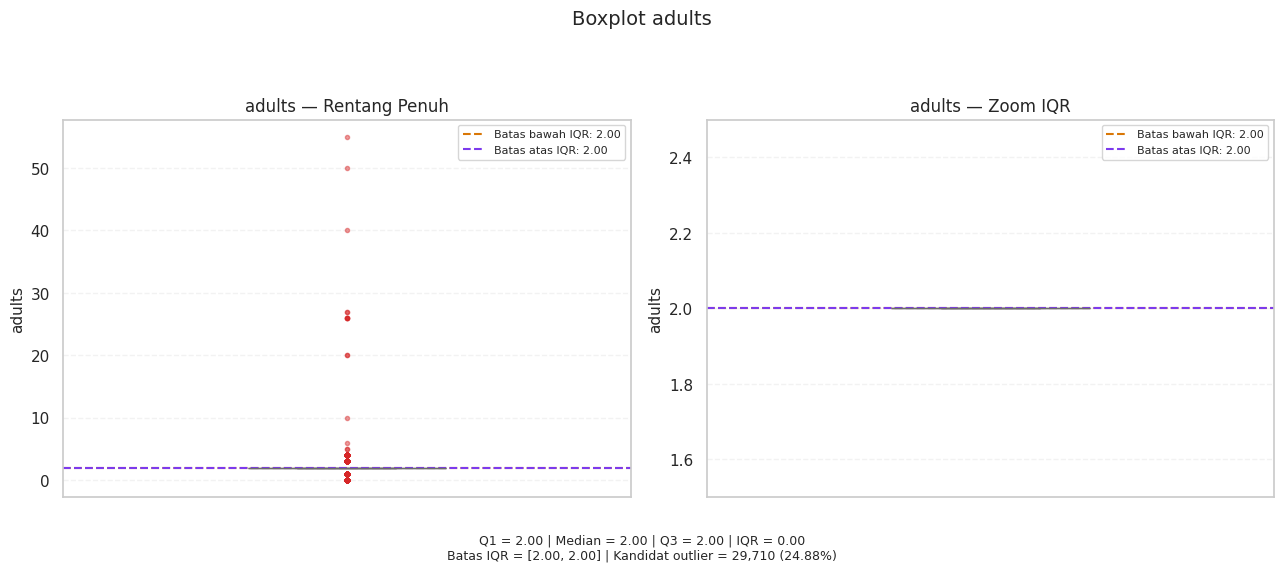

Catatan adults: IQR = 0 (Q1 = Q3). Kotak dapat tampak seperti garis karena setidaknya 50% data terkonsentrasi pada nilai yang sama. Ini dapat terjadi pada variabel hitungan yang didominasi angka nol; bukan otomatis kesalahan grafik.


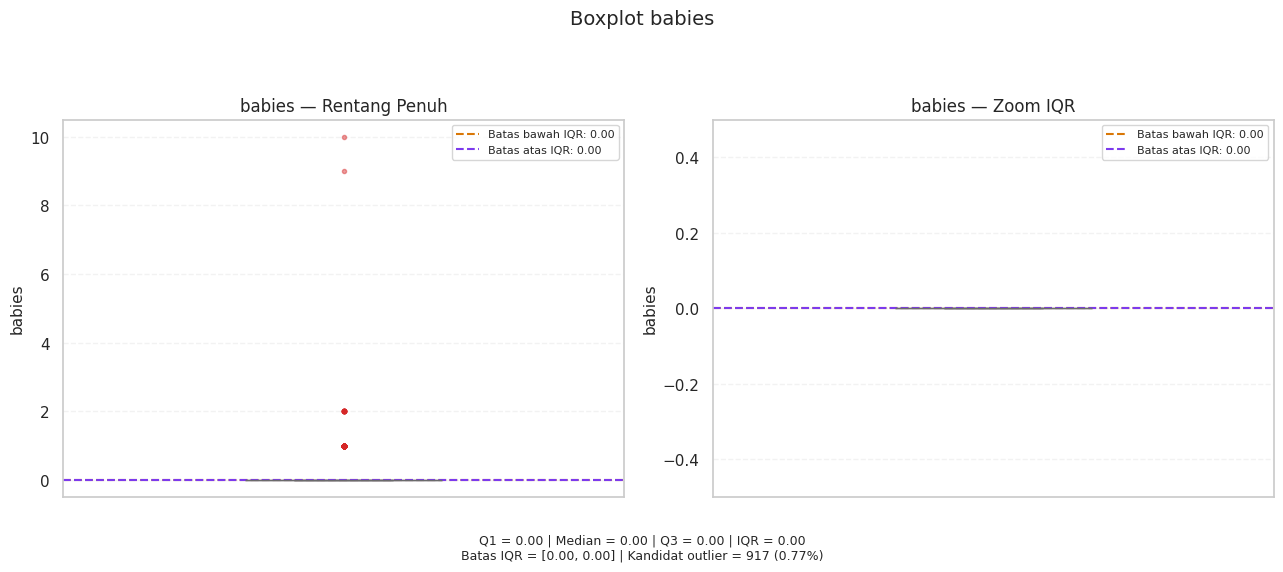

Catatan babies: IQR = 0 (Q1 = Q3). Kotak dapat tampak seperti garis karena setidaknya 50% data terkonsentrasi pada nilai yang sama. Ini dapat terjadi pada variabel hitungan yang didominasi angka nol; bukan otomatis kesalahan grafik.


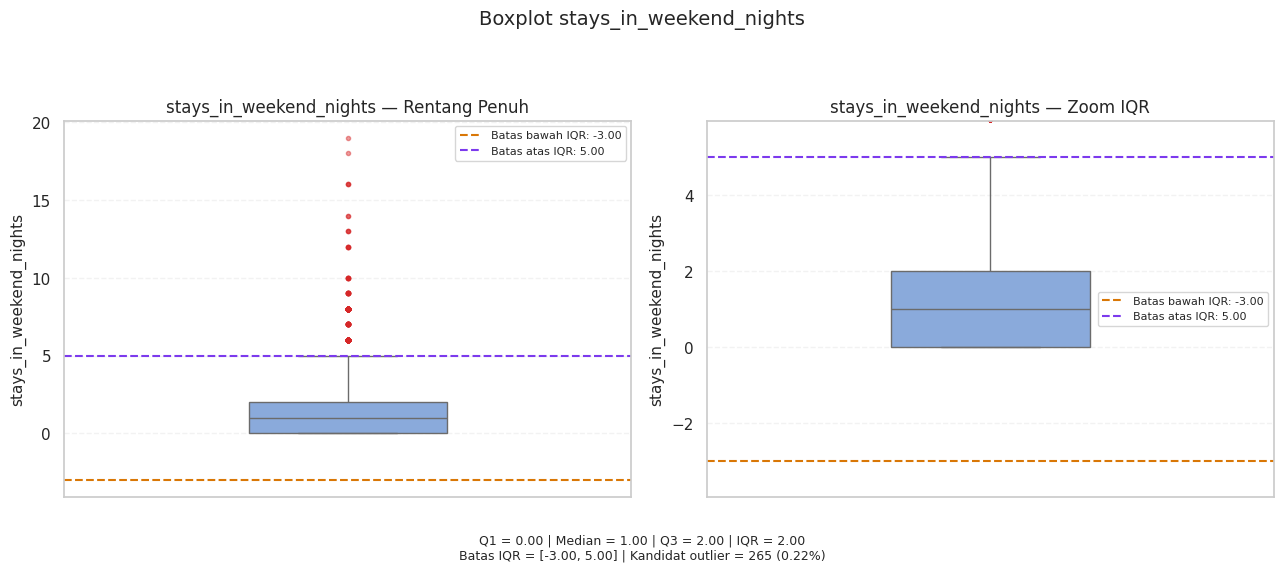

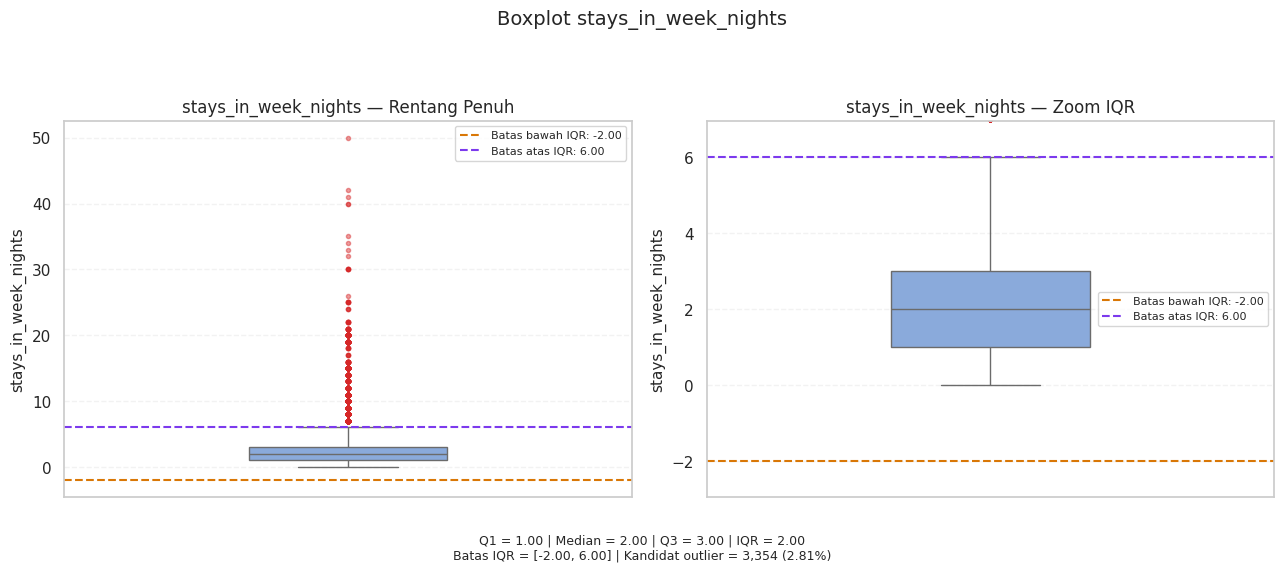

In [18]:
kolom_boxplot = [
    "adr", "lead_time", "children", "adults", "babies",
    "stays_in_weekend_nights", "stays_in_week_nights"
]

for kolom in [c for c in kolom_boxplot if c in df.columns]:
    data = pd.to_numeric(df[kolom], errors="coerce").dropna()
    data = data[np.isfinite(data)]
    if data.empty:
        print(f"{kolom}: tidak ada data valid.")
        continue

    q1, q3 = data.quantile(0.25), data.quantile(0.75)
    median = data.median()
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    outlier = data[(data < batas_bawah) | (data > batas_atas)]
    pct_outlier = len(outlier) / len(data) * 100

    flierprops = {
        "marker": "o", "markerfacecolor": "#D62728",
        "markeredgecolor": "#D62728", "markersize": 3, "alpha": 0.45
    }

    # Dua panel: rentang penuh dan pada rentang kuartil/batas IQR.
    # Panel rentang penuh memperlihatkan seluruh data
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

    for ax in axes:
        sns.boxplot(
            y=data, color="#7DA7E8", width=0.35, showfliers=True,
            flierprops=flierprops, ax=ax
        )
        ax.axhline(batas_bawah, color="#D97706", linestyle="--",
                   linewidth=1.5, label=f"Batas bawah IQR: {batas_bawah:.2f}")
        ax.axhline(batas_atas, color="#7C3AED", linestyle="--",
                   linewidth=1.5, label=f"Batas atas IQR: {batas_atas:.2f}")
        ax.set_ylabel(kolom)
        ax.grid(axis="y", linestyle="--", alpha=0.25)
        ax.legend(loc="best", fontsize=8)

    # Rentang penuh.
    full_min = min(float(data.min()), float(batas_bawah))
    full_max = max(float(data.max()), float(batas_atas))
    full_padding = max((full_max - full_min) * 0.05, 0.5)
    axes[0].set_ylim(full_min - full_padding, full_max + full_padding)
    axes[0].set_title(f"{kolom} — Rentang Penuh", fontsize=12)

    # fokus pada pagar IQR dan area sekitar kuartil.
    # Batas sumbu tetap mencakup kedua pagar IQR.
    zoom_min = min(float(batas_bawah), float(q1))
    zoom_max = max(float(batas_atas), float(q3))
    zoom_padding = max((zoom_max - zoom_min) * 0.12, 0.5)
    axes[1].set_ylim(zoom_min - zoom_padding, zoom_max + zoom_padding)
    axes[1].set_title(f"{kolom} — Zoom IQR", fontsize=12)

    fig.suptitle(f"Boxplot {kolom}", fontsize=14, y=1.02)
    catatan = (
        f"Q1 = {q1:.2f} | Median = {median:.2f} | Q3 = {q3:.2f} | IQR = {iqr:.2f}\n"
        f"Batas IQR = [{batas_bawah:.2f}, {batas_atas:.2f}] | "
        f"Kandidat outlier = {len(outlier):,} ({pct_outlier:.2f}%)"
    )
    fig.text(0.5, 0.015, catatan, ha="center", va="bottom", fontsize=9)
    plt.tight_layout(rect=[0, 0.10, 1, 0.96])
    plt.show()

    if iqr == 0:
        print(
            f"Catatan {kolom}: IQR = 0 (Q1 = Q3). Kotak dapat tampak seperti garis "
            "karena setidaknya 50% data terkonsentrasi pada nilai yang sama. "
            "Ini dapat terjadi pada variabel hitungan yang didominasi angka nol; "
            "bukan otomatis kesalahan grafik."
        )


## 12. Skewness dan kurtosis

In [19]:
shape_report = pd.DataFrame({
    "Skewness": df[numeric_cols].skew(),
    "Kurtosis (Excess)": df[numeric_cols].kurtosis()
})
display(shape_report.sort_values("Skewness").round(3))

,Skewness,Kurtosis (Excess)
arrival_date_year,-0.233,-0.995
arrival_date_week_number,-0.010,-0.986
arrival_date_day_of_month,-0.002,-1.187
is_canceled,0.537,-1.712
company,0.602,-0.491
agent,1.089,-0.007
lead_time,1.347,1.696
total_of_special_requests,1.349,1.493
stays_in_weekend_nights,1.380,7.174
stays_in_week_nights,2.862,24.285


## 13. QQ plot ADR dan uji normalitas

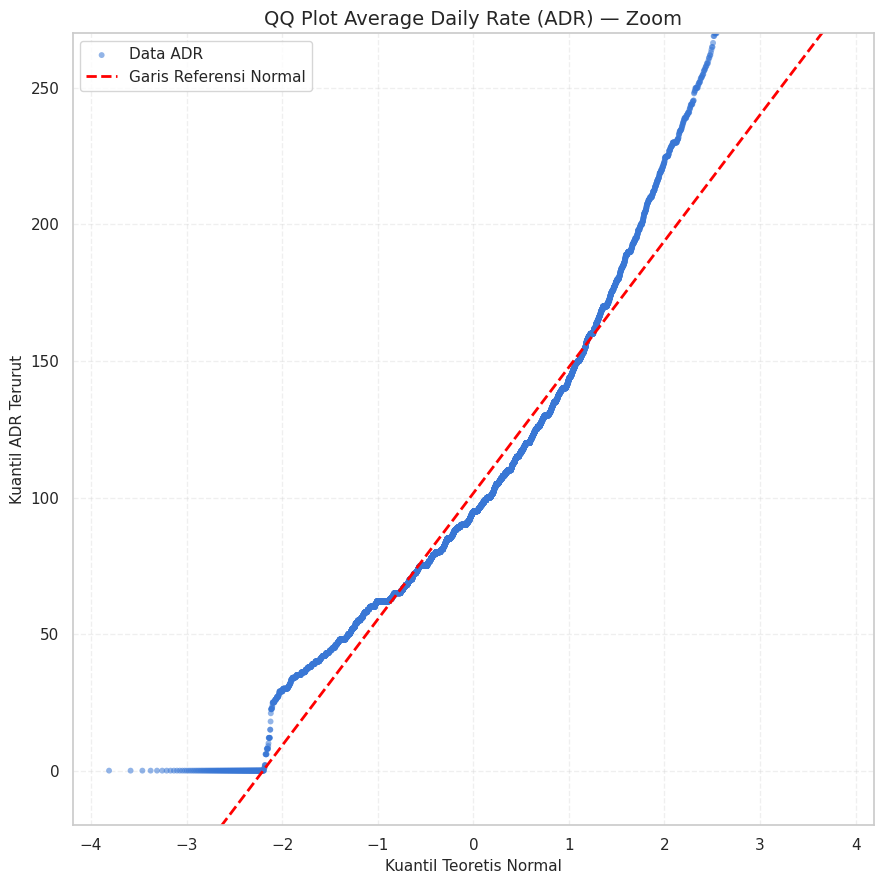

Jumlah data sampel: 10000
Statistik uji normalitas: 1958.0141
P-value: 0
Kesimpulan: data tidak berdistribusi normal (α = 0,05).


In [20]:
if "adr" in df.columns:
    x = pd.to_numeric(df["adr"], errors="coerce").dropna()
    x = x[np.isfinite(x)]
    sample = x.sample(n=min(10000, len(x)), random_state=42)

    (theoretical, ordered), (slope, intercept, r) = stats.probplot(sample, dist="norm")
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.scatter(theoretical, ordered, color="#3977D5", alpha=0.55,
               s=18, edgecolors="none", label="Data ADR")
    line_x = np.array([theoretical.min(), theoretical.max()])
    ax.plot(line_x, slope * line_x + intercept, color="red",
            linestyle="--", linewidth=2, label="Garis Referensi Normal")

    # Zoom sumbu Y pada persentil 1-99; sumbu X tetap mencakup kuantil teoretis.
    y_min, y_max = np.percentile(ordered, [1, 99])
    padding = (y_max - y_min) * 0.08
    ax.set_ylim(y_min - padding, y_max + padding)
    ax.set_title("QQ Plot Average Daily Rate (ADR) — Zoom", fontsize=14)
    ax.set_xlabel("Kuantil Teoretis Normal")
    ax.set_ylabel("Kuantil ADR Terurut")
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    print("Jumlah data sampel:", len(sample))
    if len(sample) >= 8:
        stat, p_value = stats.normaltest(sample)
        print(f"Statistik uji normalitas: {stat:.4f}")
        print(f"P-value: {p_value:.6g}")
        if p_value < 0.05:
            print("Kesimpulan: data tidak berdistribusi normal (α = 0,05).")
        else:
            print("Kesimpulan: data berdistribusi normal (α = 0,05).")
    else:
        print("Sampel terlalu sedikit untuk stats.normaltest.")

## 14. Ringkasan kandidat outlier dengan metode IQR

In [21]:
def analisis_iqr(data, columns):
    hasil = []
    for col in columns:
        x = pd.to_numeric(data[col], errors="coerce").dropna()
        if x.empty:
            continue
        q1, q3 = x.quantile(0.25), x.quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (x < lower) | (x > upper)
        hasil.append({
            "Variabel": col, "Q1": q1, "Q3": q3, "IQR": iqr,
            "Batas Bawah": lower, "Batas Atas": upper,
            "Jumlah Outlier": int(mask.sum()),
            "Persentase Outlier (%)": mask.mean() * 100
        })
    return pd.DataFrame(hasil)

iqr_report = analisis_iqr(df, numeric_cols)
display(iqr_report.sort_values("Persentase Outlier (%)", ascending=False).round(3))

,Variabel,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase Outlier (%)
7,adults,2.000,2.000,0.000,2.000,2.000,29710,24.885
13,booking_changes,0.000,0.000,0.000,0.000,0.000,18076,15.140
8,children,0.000,0.000,0.000,0.000,0.000,8590,7.195
18,required_car_parking_spaces,0.000,0.000,0.000,0.000,0.000,7416,6.212
11,previous_cancellations,0.000,0.000,0.000,0.000,0.000,6484,5.431
10,is_repeated_guest,0.000,0.000,0.000,0.000,0.000,3810,3.191
17,adr,69.290,126.000,56.710,-15.775,211.065,3793,3.177
16,days_in_waiting_list,0.000,0.000,0.000,0.000,0.000,3698,3.097
12,previous_bookings_not_canceled,0.000,0.000,0.000,0.000,0.000,3620,3.032
6,stays_in_week_nights,1.000,3.000,2.000,-2.000,6.000,3354,2.809


## 15. Contoh observasi kandidat outlier ADR

In [22]:
if "adr" in df.columns:
    x = pd.to_numeric(df["adr"], errors="coerce")
    valid = x.dropna()
    q1, q3 = valid.quantile(0.25), valid.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    outlier_adr = df.loc[x.notna() & ((x < lower) | (x > upper))].copy()
    print("Jumlah kandidat outlier ADR:", len(outlier_adr))
    display(outlier_adr.head(10))

Jumlah kandidat outlier ADR: 3793


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
140,Resort Hotel,0,44,2015,July,28,5,2,0,3,0.000,0,HB,PRT,Online TA,TA/TO,0,0,0,G,G,3,No Deposit,240.000,NaN,0,Transient,225.000,2,0,Check-Out,07-07-15
303,Resort Hotel,0,79,2015,July,28,11,2,6,2,2.000,0,HB,PRT,Direct,Direct,0,0,0,G,G,1,No Deposit,250.000,NaN,0,Transient,213.750,0,0,Check-Out,19-07-15
396,Resort Hotel,0,317,2015,July,29,14,1,5,2,2.000,0,HB,PRT,Direct,TA/TO,0,0,0,H,G,1,No Deposit,240.000,NaN,0,Transient,230.670,1,2,Check-Out,20-07-15
412,Resort Hotel,0,37,2015,July,29,15,2,6,2,2.000,0,BB,GBR,Online TA,TA/TO,0,0,0,H,H,0,No Deposit,240.000,NaN,0,Transient,216.130,1,0,Check-Out,23-07-15
523,Resort Hotel,0,0,2015,July,29,18,0,1,2,2.000,0,FB,PRT,Direct,Direct,0,0,0,C,C,0,No Deposit,NaN,NaN,0,Transient,249.000,0,0,Check-Out,19-07-15
526,Resort Hotel,0,73,2015,July,29,18,2,5,2,1.000,0,FB,PRT,Direct,Direct,0,0,0,D,D,0,No Deposit,NaN,NaN,0,Transient,241.500,0,2,Check-Out,25-07-15
558,Resort Hotel,1,24,2015,July,30,19,2,4,2,2.000,0,BB,PRT,Online TA,TA/TO,0,0,0,G,G,0,No Deposit,240.000,NaN,0,Transient,214.000,0,0,Canceled,29-06-15
580,Resort Hotel,1,41,2015,July,30,20,1,5,2,2.000,0,BB,PRT,Online TA,TA/TO,0,0,0,G,G,0,No Deposit,240.000,NaN,0,Transient,214.000,0,1,Canceled,22-06-15
584,Resort Hotel,1,28,2015,July,30,20,2,5,2,1.000,0,FB,PRT,Direct,Direct,0,0,0,F,F,0,No Deposit,NaN,NaN,0,Transient,240.640,0,0,Canceled,20-07-15
632,Resort Hotel,0,34,2015,July,30,23,2,6,3,0.000,0,HB,ROU,Offline TA/TO,TA/TO,0,0,0,D,D,1,No Deposit,171.000,NaN,0,Transient,217.050,1,1,Check-Out,31-07-15


## 16. Rekomendasi awal penanganan variabel numerik

In [23]:
recommendations = []
for col in numeric_cols:
    x = pd.to_numeric(df[col], errors="coerce")
    valid = x.dropna()
    missing_pct = x.isna().mean() * 100

    if valid.empty:
        skewness, outlier_pct = np.nan, np.nan
        metode = "Evaluasi: tidak ada data valid"
    else:
        skewness = valid.skew()
        q1, q3 = valid.quantile(0.25), valid.quantile(0.75)
        iqr = q3 - q1
        if iqr > 0:
            lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            outlier_pct = ((valid < lower) | (valid > upper)).mean() * 100
        else:
            outlier_pct = 0.0

        if missing_pct == 0:
            metode = "Tidak perlu imputasi"
        elif missing_pct >= 30:
            metode = "Evaluasi khusus: missing tinggi"
        elif abs(skewness) >= 1 or outlier_pct >= 5:
            metode = "Median (kandidat; tinjau konteks)"
        else:
            metode = "Mean (kandidat; tinjau konteks)"

    recommendations.append({
        "Variabel": col, "Missing (%)": round(missing_pct, 2),
        "Skewness": round(skewness, 3) if pd.notna(skewness) else np.nan,
        "Outlier (%)": round(outlier_pct, 2) if pd.notna(outlier_pct) else np.nan,
        "Rekomendasi": metode
    })

recommendation_df = pd.DataFrame(recommendations)
display(recommendation_df)

,Variabel,Missing (%),Skewness,Outlier (%),Rekomendasi
0,is_canceled,0.000,0.537,0.000,Tidak perlu imputasi
1,lead_time,0.000,1.347,2.520,Tidak perlu imputasi
2,arrival_date_year,0.000,-0.233,0.000,Tidak perlu imputasi
3,arrival_date_week_number,0.000,-0.010,0.000,Tidak perlu imputasi
4,arrival_date_day_of_month,0.000,-0.002,0.000,Tidak perlu imputasi
5,stays_in_weekend_nights,0.000,1.380,0.220,Tidak perlu imputasi
6,stays_in_week_nights,0.000,2.862,2.810,Tidak perlu imputasi
7,adults,0.000,18.318,0.000,Tidak perlu imputasi
8,children,0.000,4.113,0.000,Median (kandidat; tinjau konteks)
9,babies,0.000,24.647,0.000,Tidak perlu imputasi


## 17. Preprocessing: buat salinan dan merapikan placeholder


In [24]:
df_clean = df.copy()

# Merapikan spasi pada kolom bertipe teks
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# Mengubah placeholder kosong yang umum menjadi NaN
placeholders = ["", "NULL", "null", "NA", "N/A", "NaN", "nan"]
df_clean = df_clean.replace(placeholders, np.nan)

print("Ukuran data mentah:", df.shape)
print("Ukuran setelah normalisasi teks:", df_clean.shape)
print("Missing values setelah normalisasi:", int(df_clean.isna().sum().sum()))

Ukuran data mentah: (119390, 32)
Ukuran setelah normalisasi teks: (119390, 32)
Missing values setelah normalisasi: 129425


## 18. Penanganan duplikasi

In [25]:
duplikat_sebelum = int(df_clean.duplicated().sum())
if duplikat_sebelum > 0:
    df_clean = df_clean.drop_duplicates().copy()

print("Duplikat sebelum:", duplikat_sebelum)
print("Duplikat setelah:", int(df_clean.duplicated().sum()))
print("Dimensi setelah pemeriksaan duplikasi:", df_clean.shape)

Duplikat sebelum: 31994
Duplikat setelah: 0
Dimensi setelah pemeriksaan duplikasi: (87396, 32)


## 19. Penanganan missing values

Aturan yang digunakan di sini:
- `company` dan `agent`: diisi label `"Unknown"` agar informasi bahwa identitasnya tidak tersedia tetap eksplisit. Kolom ini berisi identifier, sehingga jangan dipakai sebagai ukuran numerik.
- `country`: diisi `"Unknown"` karena merupakan kategori negara.
- `children`: missing sangat sedikit; diisi modus dari nilai yang tersedia agar tetap berupa jumlah anak diskret. Nilai imputasi dicatat.
- Kolom lain yang masih missing tidak diisi secara otomatis; hasilnya ditampilkan untuk keputusan lanjutan.



In [26]:
imputation_log = []

for col in ["company", "agent", "country"]:
    if col in df_clean.columns:
        missing_before = int(df_clean[col].isna().sum())
        if missing_before > 0:
            df_clean[col] = df_clean[col].fillna("Unknown")
        imputation_log.append({
            "Kolom": col,
            "Missing Sebelum": missing_before,
            "Metode": 'Label "Unknown"',
            "Nilai Imputasi": "Unknown" if missing_before else np.nan
        })

if "children" in df_clean.columns:
    x = pd.to_numeric(df_clean["children"], errors="coerce")
    missing_before = int(x.isna().sum())
    valid = x.dropna()
    if missing_before > 0 and not valid.empty:
        mode_values = valid.mode()
        nilai = mode_values.iloc[0]
        df_clean["children"] = x.fillna(nilai)
        metode = "Modus"
    else:
        nilai = np.nan
        metode = "Tidak perlu imputasi" if missing_before == 0 else "Ditunda: tidak ada nilai valid"
    imputation_log.append({
        "Kolom": "children",
        "Missing Sebelum": missing_before,
        "Metode": metode,
        "Nilai Imputasi": nilai
    })

display(pd.DataFrame(imputation_log))

,Kolom,Missing Sebelum,Metode,Nilai Imputasi
0,company,82137,"Label ""Unknown""",Unknown
1,agent,12193,"Label ""Unknown""",Unknown
2,country,452,"Label ""Unknown""",Unknown
3,children,4,Modus,0.000


## 20. Validasi missing values setelah preprocessing

In [27]:
remaining_missing = pd.DataFrame({
    "Jumlah Missing": df_clean.isna().sum(),
    "Persentase Missing (%)": (df_clean.isna().mean() * 100).round(2)
})
remaining_missing = remaining_missing[remaining_missing["Jumlah Missing"] > 0].sort_values(
    "Persentase Missing (%)", ascending=False
)
display(remaining_missing)

print("Jumlah baris:", df_clean.shape[0])
print("Jumlah kolom:", df_clean.shape[1])
print("Total missing values:", int(df_clean.isna().sum().sum()))

,Jumlah Missing,Persentase Missing (%)


Jumlah baris: 87396
Jumlah kolom: 32
Total missing values: 0


## 21. Perbandingan kondisi sebelum dan sesudah preprocessing

In [28]:
comparison = pd.DataFrame({
    "Kondisi": ["Dataset mentah", "Setelah preprocessing"],
    "Jumlah Baris": [len(df_raw), len(df_clean)],
    "Jumlah Kolom": [df_raw.shape[1], df_clean.shape[1]],
    "Duplikat Penuh": [int(df_raw.duplicated().sum()), int(df_clean.duplicated().sum())],
    "Total Missing": [int(df_raw.isna().sum().sum()), int(df_clean.isna().sum().sum())]
})
display(comparison)

,Kondisi,Jumlah Baris,Jumlah Kolom,Duplikat Penuh,Total Missing
0,Dataset mentah,119390,32,31994,129425
1,Setelah preprocessing,87396,32,0,0


## 22. Simpan hasil preprocessing

In [29]:
# Simpan data bersih ke CSV
output_file = "hotel_bookings_preprocessed.csv"
df_clean.to_csv(output_file, index=False)

print("File berhasil disiapkan:", output_file)

File berhasil disiapkan: hotel_bookings_preprocessed.csv


# 23. Kesimpulan

Analisis eksploratif dan preprocessing dilakukan untuk memahami karakteristik dataset pemesanan hotel, memeriksa kualitas data, serta menyiapkan data untuk analisis lanjutan. Pemeriksaan mencakup struktur dan statistik deskriptif, missing values, duplikasi, distribusi variabel, skewness dan kurtosis, QQ plot, serta kandidat pencilan menggunakan aturan 1,5 × IQR.

Boxplot perlu dibaca bersama statistik kuartil dan konteks setiap variabel. Sebaran yang sangat lebar dapat membuat kotak terlihat kecil pada grafik rentang penuh, sedangkan nilai kuartil yang sama (IQR = 0) dapat membuat kotak tampak seperti garis. Karena itu, notebook menampilkan rentang penuh dan tampilan zoom secara berdampingan. Zoom membantu membaca bagian tengah distribusi, tetapi tidak menggantikan grafik rentang penuh.

Penanganan missing values dan duplikasi diterapkan secara eksplisit, lalu hasilnya divalidasi dan dibandingkan dengan dataset mentah. Kandidat outlier tidak otomatis dihapus karena nilai ekstrem dapat mencerminkan kondisi pemesanan yang nyata. Sebelum analisis atau pemodelan berikutnya, keputusan preprocessing perlu ditinjau sesuai tujuan penelitian dan hasil aktual setelah seluruh sel notebook dijalankan.

**Catatan:** kesimpulan numerik akhir, misalnya jumlah missing values setelah preprocessing dan jumlah kandidat outlier per variabel mengacu pada output yang dihasilkan ketika notebook dijalankan menggunakan dataset yang digunakan dalam analisis.